# Do the immortal jellyfish's expanded genes decline with age in human tissues?
**Riddhika D** · Jellyfish-to-Human Rejuvenation project · pre-registered analysis

*Turritopsis dohrnii* can reverse its life cycle. Its genome has extra copies or unique variants of genes for DNA replication, DNA repair, telomere protection, redox balance and stem-cell signalling (Pascual-Torner et al., *PNAS* 2022). This notebook asks whether the **human versions** of those genes lose expression with age across human tissues (GTEx v8), more than expected by chance.

### Decided before seeing any data
| | |
|---|---|
| **Gene set** | Set A: human orthologs of *T. dohrnii* copy-number / variant genes named in PNAS 2022 |
| **Measure** | For each gene × tissue: age effect (t-value) on log2(TPM+1), adjusting for sex, ischemic time, RNA quality (RIN) and death type (Hardy scale) |
| **Set score** | Mean t-value of Set A genes, averaged across tissues |
| **Control 1** | 10,000 random gene sets matched for expression, gene length and GC content |
| **Control 2** | 10,000 random **function-matched** sets: each replication/repair/telomere/redox gene is swapped for a random human gene with the same function (GO term) and similar expression |
| **Positive result** | Set A beats **both** controls (empirical p < 0.05) |
| **Tissue level** | Same test per tissue, Benjamini–Hochberg FDR < 0.05 |
| **Exploratory only** | Single-gene rankings; GenAge comparison |

**Why Control 2 matters:** DNA replication and repair genes drop with age in most tissues just because old tissues divide less. A jellyfish-specific signal must beat other genes doing the same job.

Run: **Runtime → Run all** (about 25–45 min; most of it is downloading and reading the 1.5 GB GTEx file once). Copy the **SEND THIS TO CLAUDE** box at the end.

In [1]:
import os, io, re, gzip, json, time, zipfile, warnings, requests
import numpy as np, pandas as pd
from scipy import stats
warnings.filterwarnings('ignore'); os.makedirs('data', exist_ok=True)
REPORT = []
def note(s): print(s); REPORT.append(str(s))
RNG = np.random.default_rng(2026)
N_PERM = 10000

# ---- Set A: T. dohrnii copy-number / variant genes named in Pascual-Torner et al. PNAS 2022 (main text) ----
# Human gene symbols. NOTE: the shelterin protein TPP1 is encoded by the human gene ACD (not the lysosomal TPP1).
# Check against the paper's Dataset S1 and add any missing genes before the final run.
SET_A = {
    'replication': ['POLD1', 'POLA2', 'TOP3B', 'RFC3'],
    'repair':      ['XRCC5', 'GEN1', 'RAD51C', 'MSH2', 'ATM'],
    'telomere':    ['GAR1', 'POT1', 'ACD'],
    'redox':       ['TXN', 'GSR'],
    'other':       ['GLI3', 'BMP7', 'PSEN1', 'TUBG1', 'CLASP1', 'SPAST', 'MORC3', 'HECW2'],
}
GO_POOL = {'replication': 'GO:0006260', 'repair': 'GO:0006281', 'telomere': 'GO:0000723', 'redox': 'GO:0045454'}
SETA = [g for v in SET_A.values() for g in v]
CAT = {g: c for c, v in SET_A.items() for g in v}
# label check: genes with well-known age trends in human tissues
POS_UP = ['CDKN2A', 'C4A', 'C4B', 'EDA2R']     # rise with age
POS_DOWN = ['COL1A1', 'COL3A1', 'COL1A2']      # fall with age (skin, arteries, fibroblast-rich tissues)
note(f'Set A: {len(SETA)} genes in {len(SET_A)} groups')

Set A: 22 genes in 5 groups


## 1. Download GTEx v8 (open access)
Expression (gene TPM), sample attributes and donor phenotypes. Public GTEx gives age in 10-year groups (20–29 … 60–69); we use the midpoint.

In [2]:
def fetch(urls, fn, stream=False):
    if os.path.exists(fn) and os.path.getsize(fn) > 1000: return fn
    for u in urls:
        try:
            with requests.get(u, stream=True, timeout=120) as r:
                if r.status_code != 200: print('  ', r.status_code, u); continue
                with open(fn + '.part', 'wb') as f:
                    for ch in r.iter_content(1 << 22): f.write(ch)
            os.rename(fn + '.part', fn); print('downloaded', fn, f'{os.path.getsize(fn) / 1e6:.0f} MB'); return fn
        except Exception as e: print('  failed', u, str(e)[:80])
    raise RuntimeError(f'could not download {fn}')

B1 = 'https://storage.googleapis.com/adult-gtex'
B0 = 'https://storage.googleapis.com/gtex_analysis_v8'
TPM = fetch([f'{B1}/bulk-gex/v8/rna-seq/GTEx_Analysis_2017-06-05_v8_RNASeQCv1.1.9_gene_tpm.gct.gz',
             f'{B0}/rna_seq_data/GTEx_Analysis_2017-06-05_v8_RNASeQCv1.1.9_gene_tpm.gct.gz'], 'data/gtex_tpm.gct.gz')
SA = fetch([f'{B1}/annotations/v8/metadata-files/GTEx_Analysis_v8_Annotations_SampleAttributesDS.txt',
            f'{B0}/annotations/GTEx_Analysis_v8_Annotations_SampleAttributesDS.txt'], 'data/sample_attr.txt')
SP = fetch([f'{B1}/annotations/v8/metadata-files/GTEx_Analysis_v8_Annotations_SubjectPhenotypesDS.txt',
            f'{B0}/annotations/GTEx_Analysis_v8_Annotations_SubjectPhenotypesDS.txt'], 'data/subject_pheno.txt')

downloaded data/gtex_tpm.gct.gz 1626 MB
downloaded data/sample_attr.txt 12 MB
downloaded data/subject_pheno.txt 0 MB


In [3]:
sa = pd.read_csv(SA, sep='\t', low_memory=False)
sp = pd.read_csv(SP, sep='\t')
sa['SUBJID'] = sa.SAMPID.str.split('-').str[:2].str.join('-')
meta = sa[['SAMPID', 'SUBJID', 'SMTSD', 'SMTSISCH', 'SMRIN']].merge(sp, on='SUBJID', how='inner')
meta['age'] = meta.AGE.str.split('-').str[0].astype(float) + 4.5
meta['sex'] = (meta.SEX == 2).astype(float)
meta = meta[~meta.SMTSD.str.startswith('Cells')].dropna(subset=['age', 'SMTSISCH', 'SMRIN'])
meta['DTHHRDY'] = meta.DTHHRDY.fillna(-1).astype(int)
note(f'GTEx: {meta.SUBJID.nunique()} donors, {len(meta)} tissue samples with full covariates; age groups: '
     + ', '.join(f'{int(a - 4.5)}s n={n}' for a, n in meta.drop_duplicates("SUBJID").age.value_counts().sort_index().items()))

GTEx: 971 donors, 19052 tissue samples with full covariates; age groups: 20s n=83, 30s n=76, 40s n=150, 50s n=312, 60s n=317, 70s n=33


## 2. Gene annotation (protein-coding, length, GC) and function pools
From Ensembl BioMart and MyGene.info (GO terms). Used to build the matched random sets.

In [4]:
def biomart():
    fn = 'data/biomart.tsv'
    if os.path.exists(fn): return pd.read_csv(fn, sep='\t')
    xml = ('<?xml version="1.0" encoding="UTF-8"?><!DOCTYPE Query><Query virtualSchemaName="default" formatter="TSV" header="1" uniqueRows="1">'
           '<Dataset name="hsapiens_gene_ensembl" interface="default"><Attribute name="ensembl_gene_id"/><Attribute name="external_gene_name"/>'
           '<Attribute name="gene_biotype"/><Attribute name="start_position"/><Attribute name="end_position"/>'
           '<Attribute name="percentage_gene_gc_content"/></Dataset></Query>')
    for host in ['https://www.ensembl.org', 'https://useast.ensembl.org', 'https://asia.ensembl.org']:
        try:
            r = requests.get(f'{host}/biomart/martservice', params={'query': xml}, timeout=300)
            if r.ok and r.text.startswith('Gene stable ID'):
                open(fn, 'w').write(r.text); return pd.read_csv(fn, sep='\t')
        except Exception as e: print('  biomart', host, str(e)[:60])
    return None

bm = biomart()
if bm is not None:
    bm.columns = ['ens', 'symbol', 'biotype', 'start', 'end', 'gc']
    bm['length'] = bm.end - bm.start + 1
    ANN = bm.drop_duplicates('ens').set_index('ens')
    note(f'BioMart: {len(ANN)} genes, {(ANN.biotype == "protein_coding").sum()} protein-coding')
else:
    ANN = None; note('BioMart unavailable: matching will use expression only')

def go_genes(go):
    # all human genes annotated to a GO term or its child terms (Ensembl BioMart; QuickGO as fallback)
    fn = f'data/go2_{go.replace(":", "")}.json'
    if os.path.exists(fn): return set(json.load(open(fn)))
    out = set()
    xml = ('<?xml version="1.0" encoding="UTF-8"?><!DOCTYPE Query><Query virtualSchemaName="default" formatter="TSV" header="0" uniqueRows="1">'
           f'<Dataset name="hsapiens_gene_ensembl" interface="default"><Filter name="go_parent_term" value="{go}"/>'
           '<Attribute name="external_gene_name"/></Dataset></Query>')
    for host in ['https://www.ensembl.org', 'https://useast.ensembl.org', 'https://asia.ensembl.org']:
        try:
            r = requests.get(f'{host}/biomart/martservice', params={'query': xml}, timeout=300)
            if r.ok and '<' not in r.text[:50]:
                out = {x.strip() for x in r.text.splitlines() if x.strip()}
                if out: break
        except Exception as e: print('  biomart GO', host, str(e)[:60])
    if not out:
        try:
            r = requests.get('https://www.ebi.ac.uk/QuickGO/services/annotation/downloadSearch',
                             params={'goId': go, 'taxonId': 9606, 'goUsage': 'descendants', 'geneProductType': 'protein'},
                             headers={'Accept': 'text/tsv'}, timeout=300)
            out = {l.split('\t')[2] for l in r.text.splitlines()[1:] if l.count('\t') > 2}
        except Exception as e: print('  QuickGO', str(e)[:60])
    json.dump(sorted(out), open(fn, 'w')); return out
POOL = {c: go_genes(go) for c, go in GO_POOL.items()}
note('function pools (GO): ' + ', '.join(f'{c}={len(v)} genes' for c, v in POOL.items()))
if min(len(v) for v in POOL.values()) < 20: note('WARNING: a function pool is empty or tiny; control 2 will fall back to control 1 for those genes')

BioMart: 86411 genes, 23272 protein-coding
function pools (GO): replication=135 genes, repair=515 genes, telomere=97 genes, redox=42 genes


## 3. Age effect for every gene in every tissue (one pass through the GTEx file)
For each tissue: log2(TPM+1) ~ age + sex + ischemic time + RIN + Hardy scale. Only genes with median TPM ≥ 1 in that tissue are tested. Tissues need ≥ 100 samples.

In [5]:
with gzip.open(TPM, 'rt') as f:
    f.readline(); f.readline(); header = f.readline().rstrip('\n').split('\t')
cols = header[2:]
col_idx = {s: i for i, s in enumerate(cols)}
meta = meta[meta.SAMPID.isin(col_idx)]
tissues = [t for t, n in meta.SMTSD.value_counts().items() if n >= 100]
DESIGN = {}
for t in tissues:
    m = meta[meta.SMTSD == t]
    X = pd.DataFrame({'const': 1.0, 'age': m.age.values, 'sex': m.sex.values,
                      'isch': m.SMTSISCH.values, 'rin': m.SMRIN.values})
    hd = pd.get_dummies(m.DTHHRDY.values, prefix='h', drop_first=True, dtype=float)
    X = pd.concat([X, hd.reset_index(drop=True)], axis=1)
    X = X.loc[:, (X.std() > 0) | (X.columns == 'const')].values
    XtX = np.linalg.pinv(X.T @ X)
    DESIGN[t] = (np.array([col_idx[s] for s in m.SAMPID]), X, XtX @ X.T, XtX[1, 1], len(m) - X.shape[1])
note(f'tissues tested (>=100 samples): {len(tissues)}')

keep_ens = None
if ANN is not None: keep_ens = set(ANN.index[ANN.biotype == 'protein_coding'])
genes, syms, T_rows, mean_expr, buf, bsym = [], [], [], [], [], []

def flush():
    if not buf: return
    Y = np.vstack(buf).astype(np.float32); Y = np.log2(Y + 1)
    tt = np.full((len(buf), len(tissues)), np.nan, np.float32)
    for j, t in enumerate(tissues):
        idx, X, P, c11, df = DESIGN[t]
        y = Y[:, idx]
        expressed = np.median(y, axis=1) >= 1.0
        if not expressed.any(): continue
        ye = y[expressed]
        beta = ye @ P.T
        resid = ye - beta @ X.T
        s2 = (resid ** 2).sum(1) / df
        tt[expressed, j] = beta[:, 1] / np.sqrt(s2 * c11 + 1e-12)
    T_rows.append(tt); mean_expr.extend(Y.mean(1)); genes.extend(bsym_ens); syms.extend(bsym)
    buf.clear(); bsym.clear(); bsym_ens.clear()

bsym_ens = []
t0 = time.time(); n = 0
with gzip.open(TPM, 'rt') as f:
    for _ in range(3): f.readline()
    for line in f:
        a = line.split('\t', 2)
        ens = a[0].split('.')[0]
        if keep_ens is not None and ens not in keep_ens: continue
        buf.append(np.array(a[2].split('\t'), dtype=np.float32)); bsym.append(a[1]); bsym_ens.append(ens)
        n += 1
        if len(buf) == 1000:
            flush(); print(f'  {n} genes, {time.time() - t0:.0f}s')
flush()
T = pd.DataFrame(np.vstack(T_rows), index=syms, columns=tissues)
T = T[~T.index.duplicated()]
EXPR = pd.Series(mean_expr, index=syms); EXPR = EXPR[~EXPR.index.duplicated()]
T.to_csv('data/age_t_by_gene_tissue.csv.gz')
note(f'age effects computed: {T.shape[0]} genes x {T.shape[1]} tissues ({time.time() - t0:.0f}s)')

tissues tested (>=100 samples): 46
  1000 genes, 8s
  2000 genes, 14s
  3000 genes, 22s
  4000 genes, 28s
  5000 genes, 36s
  6000 genes, 42s
  7000 genes, 50s
  8000 genes, 56s
  9000 genes, 64s
  10000 genes, 70s
  11000 genes, 77s
  12000 genes, 83s
  13000 genes, 91s
  14000 genes, 98s
  15000 genes, 106s
  16000 genes, 112s
  17000 genes, 119s
  18000 genes, 126s
  19000 genes, 133s
age effects computed: 19208 genes x 46 tissues (137s)


### Label check: do genes with known age trends behave as expected?
If this fails, stop: something is wrong with the age labels or the model.

In [6]:
def gene_line(g, tis=None):
    if g not in T.index: return f'{g}: not found'
    r = T.loc[g] if tis is None else T.loc[g, tis]
    r = r.dropna(); return f'{g}: mean t {r.mean():+.2f}, rises in {(r > 2).sum()} / falls in {(r < -2).sum()} of {len(r)} tissues'
# v2: collagen decline is expected in skin and arteries, not averaged over all 46 tissues (v1 check was mis-specified)
COLL_TIS = [t for t in T.columns if t.startswith(('Skin', 'Artery'))]
for g in POS_UP: note('expected UP (all tissues)        ' + gene_line(g))
for g in POS_DOWN: note('expected DOWN (skin + arteries) ' + gene_line(g, COLL_TIS))
up = np.nanmean([T.loc[g].mean() for g in POS_UP if g in T.index])
dn = np.nanmean([T.loc[g, COLL_TIS].mean() for g in POS_DOWN if g in T.index])
note(f'LABEL CHECK: {"PASS" if up > 0 and dn < 0 else "FAIL - do not interpret results"} (up genes mean t {up:+.2f}; collagens in skin/arteries {dn:+.2f})')

expected UP (all tissues)        CDKN2A: mean t +4.43, rises in 9 / falls in 0 of 12 tissues
expected UP (all tissues)        C4A: mean t +1.80, rises in 19 / falls in 0 of 41 tissues
expected UP (all tissues)        C4B: mean t +1.17, rises in 10 / falls in 0 of 34 tissues
expected UP (all tissues)        EDA2R: mean t +5.91, rises in 28 / falls in 0 of 31 tissues
expected DOWN (skin + arteries) COL1A1: mean t +1.60, rises in 2 / falls in 0 of 5 tissues
expected DOWN (skin + arteries) COL3A1: mean t +0.76, rises in 0 / falls in 0 of 5 tissues
expected DOWN (skin + arteries) COL1A2: mean t +1.53, rises in 2 / falls in 0 of 5 tissues
LABEL CHECK: FAIL - do not interpret results (up genes mean t +3.33; collagens in skin/arteries +1.30)


## 4. Main test: Set A vs the two controls

In [7]:
present = [g for g in SETA if g in T.index]
missing = [g for g in SETA if g not in T.index]
note(f'Set A genes found in GTEx: {len(present)}/{len(SETA)}; missing: {missing}')

# matching bins over all tested genes
univ = pd.DataFrame({'expr': EXPR.reindex(T.index)})
if ANN is not None:
    a = ANN.drop_duplicates('symbol').set_index('symbol')
    univ['length'] = np.log10(a.length.reindex(univ.index)); univ['gc'] = a.gc.reindex(univ.index)
univ = univ.dropna()
for c in univ.columns: univ[c + '_bin'] = pd.qcut(univ[c].rank(method='first'), 10, labels=False)
bincols = [c for c in univ.columns if c.endswith('_bin')]
univ['bin'] = univ[bincols].astype(str).agg('-'.join, axis=1)
univ['ebin'] = univ['expr_bin']
present = [g for g in present if g in univ.index]
non_set = univ.drop(index=present, errors='ignore')
by_bin = non_set.groupby('bin').groups; by_ebin = non_set.groupby('ebin').groups

def matched_pool(g):
    b = univ.loc[g, 'bin']; pool = list(by_bin.get(b, []))
    return pool if len(pool) >= 5 else list(by_ebin[univ.loc[g, 'ebin']])
POOL1 = {g: np.array(matched_pool(g)) for g in present}
def func_pool(g):
    c = CAT[g]
    if c not in POOL: return POOL1[g]
    cand = [x for x in POOL[c] if x in non_set.index and x not in present]
    near = [x for x in cand if abs(univ.loc[x, 'ebin'] - univ.loc[g, 'ebin']) <= 2]
    return np.array(near if len(near) >= 5 else cand if len(cand) >= 5 else POOL1[g])
POOL2 = {g: func_pool(g) for g in present}
note('function-matched pool sizes: ' + ', '.join(f'{g}={len(POOL2[g])}' for g in present if CAT[g] != 'other'))

Tv = T.values; row = {g: i for i, g in enumerate(T.index)}
def set_scores(idx_matrix):
    # idx_matrix: n_perm x n_genes of row indices -> per-tissue mean t (n_perm x tissues)
    out = np.empty((idx_matrix.shape[0], Tv.shape[1]), np.float32)
    for k in range(0, idx_matrix.shape[0], 500):
        out[k:k + 500] = np.nanmean(Tv[idx_matrix[k:k + 500]], axis=1)
    return out
def draw(pools):
    return np.stack([np.array([row[x] for x in RNG.choice(pools[g], N_PERM)]) for g in present], axis=1)

obs_t = np.nanmean(Tv[[row[g] for g in present]], axis=0)
obs = np.nanmean(obs_t)
null1_t = set_scores(draw(POOL1)); null2_t = set_scores(draw(POOL2))
null1 = np.nanmean(null1_t, 1); null2 = np.nanmean(null2_t, 1)
def emp_p(x, null): return (1 + (np.abs(null - np.nanmean(null)) >= abs(x - np.nanmean(null))).sum()) / (1 + len(null))
p1, p2 = emp_p(obs, null1), emp_p(obs, null2)
pct1, pct2 = (null1 < obs).mean() * 100, (null2 < obs).mean() * 100
note(f'Set A mean age effect across tissues: t = {obs:+.3f}  (negative = declines with age)')
note(f'  Control 1 (expression/length/GC matched): null mean {null1.mean():+.3f}; Set A at {pct1:.1f}th percentile; p = {p1:.4f}')
note(f'  Control 2 (function matched):             null mean {null2.mean():+.3f}; Set A at {pct2:.1f}th percentile; p = {p2:.4f}')
verdict = ('POSITIVE: beats both controls' if p1 < 0.05 and p2 < 0.05 else
           'GENERIC: beats random genes but not function-matched genes (behaves like any replication/repair gene)' if p1 < 0.05 else
           'NULL: no difference from random genes')
note(f'PRE-REGISTERED VERDICT: {verdict}')

# DNA-maintenance core only (replication + repair + telomere), the jellyfish's main expansion
core = [g for g in present if CAT[g] in ('replication', 'repair', 'telomere')]
ci = [present.index(g) for g in core]
oc = np.nanmean(np.nanmean(Tv[[row[g] for g in core]], 0))
d1 = draw(POOL1)[:, ci]; d2 = draw(POOL2)[:, ci]
n1c = np.nanmean(set_scores(d1), 1); n2c = np.nanmean(set_scores(d2), 1)
note(f'DNA-maintenance core ({len(core)} genes): t = {oc:+.3f}; p vs control 1 = {emp_p(oc, n1c):.4f}, p vs control 2 = {emp_p(oc, n2c):.4f}')

Set A genes found in GTEx: 22/22; missing: []
function-matched pool sizes: POLD1=78, POLA2=78, TOP3B=63, RFC3=83, XRCC5=197, GEN1=203, RAD51C=266, MSH2=292, ATM=292, GAR1=63, POT1=55, ACD=63, TXN=24, GSR=28
Set A mean age effect across tissues: t = -0.003  (negative = declines with age)
  Control 1 (expression/length/GC matched): null mean +0.031; Set A at 36.8th percentile; p = 0.7240
  Control 2 (function matched):             null mean +0.032; Set A at 35.0th percentile; p = 0.7012
PRE-REGISTERED VERDICT: NULL: no difference from random genes
DNA-maintenance core (12 genes): t = +0.077; p vs control 1 = 0.8432, p vs control 2 = 0.8773


## 5. Tissue by tissue (FDR-corrected)

In [8]:
def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = p[o] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty_like(q); out[o] = np.minimum(q, 1); return out
rows = []
for j, t in enumerate(tissues):
    n1, n2 = null1_t[:, j], null2_t[:, j]
    rows.append(dict(tissue=t, setA_t=obs_t[j], p_ctrl1=emp_p(obs_t[j], n1), p_ctrl2=emp_p(obs_t[j], n2)))
TT = pd.DataFrame(rows)
TT['fdr_ctrl1'] = bh(TT.p_ctrl1); TT['fdr_ctrl2'] = bh(TT.p_ctrl2)
TT = TT.sort_values('setA_t'); TT.to_csv('data/tissue_results.csv', index=False)
sig = TT[(TT.fdr_ctrl1 < 0.05) & (TT.fdr_ctrl2 < 0.05)]
note(f'tissues where Set A beats BOTH controls (FDR<0.05): {len(sig)} of {len(TT)}' + (': ' + ', '.join(f'{r.tissue} (t={r.setA_t:+.2f})' for _, r in sig.iterrows()) if len(sig) else ''))
note('strongest declines (Set A mean t): ' + ', '.join(f'{r.tissue} {r.setA_t:+.2f}' for _, r in TT.head(5).iterrows()))
note('strongest rises: ' + ', '.join(f'{r.tissue} {r.setA_t:+.2f}' for _, r in TT.tail(3).iterrows()))

tissues where Set A beats BOTH controls (FDR<0.05): 0 of 46
strongest declines (Set A mean t): Brain - Cerebellum -2.12, Brain - Frontal Cortex (BA9) -2.10, Whole Blood -1.90, Ovary -1.79, Brain - Amygdala -1.78
strongest rises: Adipose - Visceral (Omentum) +1.81, Adipose - Subcutaneous +2.03, Muscle - Skeletal +2.52


## 6. Exploratory: single genes and the GenAge comparison
Not part of the pre-registered test. Use only to suggest follow-up.

In [9]:
G = pd.DataFrame({'mean_t': T.loc[present].mean(1), 'tissues_down': (T.loc[present] < -3).sum(1),
                  'tissues_up': (T.loc[present] > 3).sum(1), 'tissues_tested': T.loc[present].notna().sum(1),
                  'group': [CAT[g] for g in present]}).sort_values('mean_t')
G.to_csv('data/setA_genes.csv')
note('Set A genes (mean age t; tissues with |t|>3 down/up):\n' + G.round(2).to_string())

try:
    fn = fetch(['https://genomics.senescence.info/genes/human_genes.zip'], 'data/genage_human.zip')
    z = zipfile.ZipFile(fn); gname = [n for n in z.namelist() if n.endswith('.csv')][0]
    genage = [g for g in pd.read_csv(z.open(gname)).symbol if g in T.index and g not in present]
    gs = np.nanmean(np.nanmean(Tv[[row[g] for g in genage]], 0))
    note(f'GenAge human ageing genes ({len(genage)}): mean t = {gs:+.3f} vs Set A {obs:+.3f} '
         f'(GenAge at {(null1 < gs).mean() * 100:.0f}th percentile of control 1)')
except Exception as e:
    note(f'GenAge comparison skipped: {type(e).__name__}')

Set A genes (mean age t; tissues with |t|>3 down/up):
        mean_t  tissues_down  tissues_up  tissues_tested        group
PSEN1    -0.66             4           0              46        other
GAR1     -0.63             3           0              46     telomere
TXN      -0.56             3           0              46        redox
HECW2    -0.53             2           1              34        other
XRCC5    -0.52             2           0              46       repair
GEN1     -0.48             1           1              27       repair
RFC3     -0.47             4           2              45  replication
TUBG1    -0.29             0           0              46        other
MSH2     -0.28             2           2              46       repair
GSR      -0.22             3           4              46        redox
RAD51C   -0.10             1           2              45       repair
SPAST    -0.03             1           3              46        other
CLASP1    0.10             1        

## 7. Figures

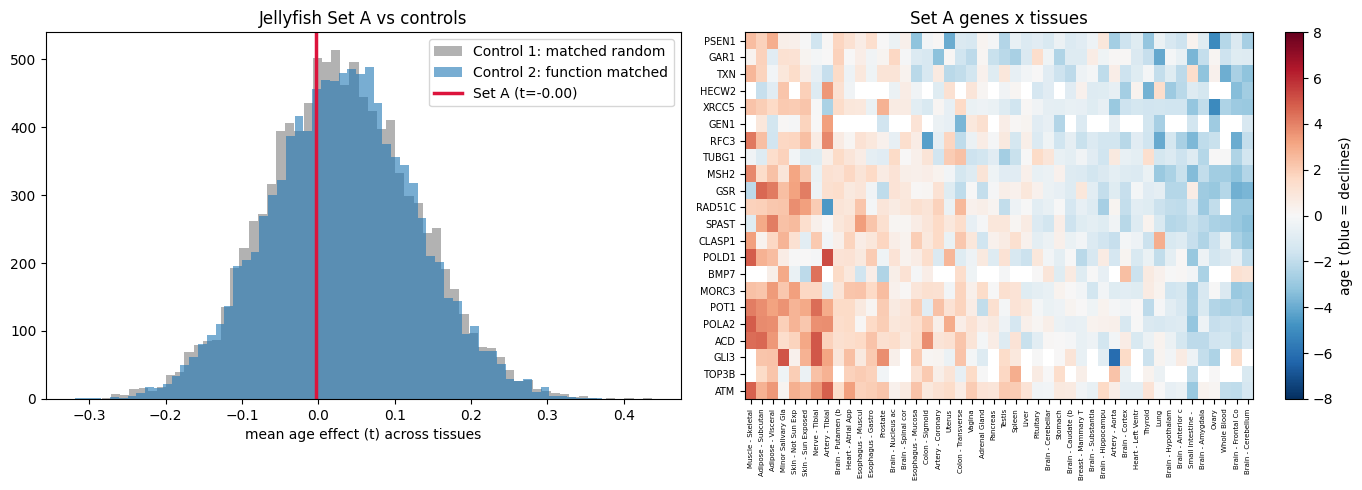

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(null1, bins=60, alpha=0.6, label='Control 1: matched random', color='gray')
ax[0].hist(null2, bins=60, alpha=0.6, label='Control 2: function matched', color='tab:blue')
ax[0].axvline(obs, color='crimson', lw=2.5, label=f'Set A (t={obs:+.2f})')
ax[0].set_xlabel('mean age effect (t) across tissues'); ax[0].legend(); ax[0].set_title('Jellyfish Set A vs controls')
H = T.loc[G.index].T
H = H.loc[TT.tissue[::-1]]
im = ax[1].imshow(H.values.T, aspect='auto', cmap='RdBu_r', vmin=-8, vmax=8)
ax[1].set_yticks(range(len(G))); ax[1].set_yticklabels(G.index, fontsize=7)
ax[1].set_xticks(range(len(H))); ax[1].set_xticklabels([t[:18] for t in H.index], rotation=90, fontsize=5)
plt.colorbar(im, ax=ax[1], label='age t (blue = declines)'); ax[1].set_title('Set A genes x tissues')
plt.tight_layout(); plt.savefig('data/figure_setA.png', dpi=150); plt.show()

## How to read the result
- **POSITIVE:** Set A declines with age more than both random and function-matched genes → jellyfish-expanded genes mark a human ageing weakness. Single-gene table gives candidates.
- **GENERIC:** beats random genes but not function-matched → the decline is just what any replication/repair gene does in ageing tissue. Honest null for the jellyfish idea.
- **NULL:** no difference from random genes.
- **Label check FAIL:** do not interpret anything.

In [11]:
print('=' * 70); print('SEND THIS TO CLAUDE'); print('=' * 70); print('\n'.join(REPORT)); print('=' * 70)

SEND THIS TO CLAUDE
Set A: 22 genes in 5 groups
GTEx: 971 donors, 19052 tissue samples with full covariates; age groups: 20s n=83, 30s n=76, 40s n=150, 50s n=312, 60s n=317, 70s n=33
BioMart: 86411 genes, 23272 protein-coding
function pools (GO): replication=135 genes, repair=515 genes, telomere=97 genes, redox=42 genes
tissues tested (>=100 samples): 46
age effects computed: 19208 genes x 46 tissues (137s)
expected UP (all tissues)        CDKN2A: mean t +4.43, rises in 9 / falls in 0 of 12 tissues
expected UP (all tissues)        C4A: mean t +1.80, rises in 19 / falls in 0 of 41 tissues
expected UP (all tissues)        C4B: mean t +1.17, rises in 10 / falls in 0 of 34 tissues
expected UP (all tissues)        EDA2R: mean t +5.91, rises in 28 / falls in 0 of 31 tissues
expected DOWN (skin + arteries) COL1A1: mean t +1.60, rises in 2 / falls in 0 of 5 tissues
expected DOWN (skin + arteries) COL3A1: mean t +0.76, rises in 0 / falls in 0 of 5 tissues
expected DOWN (skin + arteries) COL1A2: